# Do Small Proxy Models Know When GPT-3 Hallucinates?
### Token-level uncertainty, semantic-anchor weighting and two-stage screening — AI Tools for Research, Lab 02

**Aman Bhagat** · IIIT Allahabad · Google Colab, Tesla T4 (16 GB)

---

**Background.** My literature review found that token probabilities are a *partial* hallucination signal and proposed two untested ideas:
1. **Semantic-anchor weighting** (review §7.2): average uncertainty only over names, numbers and dates.
2. **Two-stage screening** (review §7.3): a cheap token score decides which sentences get an expensive semantic check.

**This study** tests both in the realistic **black-box** setting: GPT-3's own probabilities are unavailable, so small open **proxy** models re-score the text.

| | Research question |
|---|---|
| **RQ1** | Do proxy-LM (0.5B–3B) token scores detect non-factual sentences? |
| **RQ2** | Does anchor weighting (or SAR relevance weighting) beat the plain average? |
| **RQ3** | Does a token-score cascade beat random routing to SelfCheckGPT-NLI? |

**Notebook map:** 0 Setup → 1 Source code → 2 Run the pipeline → 3 Data → 4 Method → 5 Baseline validation → 6 RQ1 → 7 RQ2 → 8 RQ3 → 9 Error analysis → 10 Conclusion.

*Run with* **Runtime → Run all** *on a T4 GPU (about 30 minutes).*

## 0. Setup
Installs the spaCy English model (everything else is pre-installed in Colab) and creates the project folders.

In [ ]:
#@title Environment check and project folders
!nvidia-smi --query-gpu=name,memory.total --format=csv
!python -m spacy download en_core_web_sm -q 2>&1 | tail -1
import os
for d in ['configs', 'src/tuq', 'scripts', 'data', 'results/logs', 'paper/figures']:
    os.makedirs('/content/proj/' + d, exist_ok=True)
%cd /content/proj

name, memory.total [MiB]
Tesla T4, 15360 MiB
'Restart kernel' or 'Restart runtime' option.
/content/proj


## 1. Source code
The project is a small Python package, **`src/tuq/`**, plus numbered pipeline scripts in **`scripts/`**. Each cell below writes one file.

| File | Role |
|---|---|
| `configs/experiment.yaml` | Frozen protocol: models, metric, anchor weight α, cascade, seeds |
| `src/tuq/data.py` | Loads WikiBio, locates sentences, marks semantic anchors (spaCy) |
| `src/tuq/proxy.py` | Proxy LM forward pass → per-token −log p and entropy |
| `src/tuq/relevance.py` | SAR word relevance with a cross-encoder |
| `src/tuq/selfcheck.py` | SelfCheckGPT-NLI baseline (DeBERTa-v3-large-MNLI) |
| `src/tuq/aggregate.py` | Token → sentence scores: Avg, Max, SAR-weighted, anchor-weighted |
| `src/tuq/metrics.py` | AUC-PR (as in SelfCheckGPT), passage bootstrap, cascade |
| `scripts/01–07` | Pipeline steps, run in Section 2 |

In [ ]:
%%writefile configs/experiment.yaml
# Frozen experimental protocol (G3). Fixed BEFORE any score was computed.
# Changes after freezing must be logged in research_decisions.md.

dataset:
  hf_id: potsawee/wiki_bio_gpt3_hallucination   # SelfCheckGPT WikiBio (238 passages, 1908 sentences)
  split: evaluation                              # the only split; used purely as a test set
  label_map: {accurate: 0.0, minor_inaccurate: 0.5, major_inaccurate: 1.0}

proxy_lms:            # open-weight proxy LMs that re-score the GPT-3 text (black-box setting)
  - Qwen/Qwen2.5-0.5B
  - Qwen/Qwen2.5-1.5B
  - Qwen/Qwen2.5-3B
  - facebook/opt-1.3b
  - EleutherAI/pythia-1.4b
  - Qwen/Qwen2.5-1.5B-Instruct
proxy_prefix: "The following is a Wikipedia biography.\n\n"
proxy_dtype: float16
max_length: 1024

relevance:
  cross_encoder: cross-encoder/stsb-roberta-large   # same similarity model family as SAR (Duan et al., 2024)
  unit: word                                       # word-level removal (deviation from SAR's token level)

anchors:
  spacy_model: en_core_web_sm
  pos: [PROPN, NUM]
  entity_labels: [PERSON, NORP, FAC, ORG, GPE, LOC, PRODUCT, EVENT, WORK_OF_ART, LAW, LANGUAGE, DATE, TIME, PERCENT, MONEY, QUANTITY, ORDINAL, CARDINAL]
  alpha_primary: 0.0                 # weight of non-anchor tokens (0 = anchors only); fixed a priori
  alpha_sensitivity: [0.0, 0.1, 0.25, 0.5, 1.0]

selfcheck_nli:
  model: potsawee/deberta-v3-large-mnli
  n_samples: 20
  n_sensitivity: [1, 2, 3, 5, 10, 20]
  batch_size: 32

cascade:
  stage1_score: "Qwen/Qwen2.5-3B::avg_ent"   # pre-specified: Avg(H) of the largest proxy (best proxy family in SelfCheckGPT Table 2)
  flag_fractions: [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
  random_control_seeds: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

evaluation:
  primary_metric: AUC-PR NonFact (higher is better), sklearn precision_recall_curve + auc, as in SelfCheckGPT
  secondary: [AUC-PR NonFact*, AUC-PR Factual, passage Pearson, passage Spearman, AUROC NonFact]
  bootstrap_resamples: 1000
  bootstrap_unit: passage
  seed: 0

Writing configs/experiment.yaml


In [ ]:
%%writefile src/tuq/__init__.py
"""Token-level uncertainty (TUQ) for sentence-level hallucination detection."""

Writing src/tuq/__init__.py


In [ ]:
%%writefile src/tuq/data.py
"""Load the SelfCheckGPT WikiBio data and attach character offsets, words and anchors.

Output (data/wikibio_prepared.json): list of passages
  {pid, text, samples[20], sentences:[{text, start, end, label, score, words:[[s,e],...], anchor:[0/1,...]}]}
Offsets are character offsets into `text` (= gpt3_text).
"""
import json
import re

LABEL_SCORE = {"accurate": 0.0, "minor_inaccurate": 0.5, "major_inaccurate": 1.0}
WORD_RE = re.compile(r"\S+")


def load_raw():
    from datasets import load_dataset
    ds = load_dataset("potsawee/wiki_bio_gpt3_hallucination")
    split = list(ds.keys())[0]
    return ds[split], split


def locate_sentences(text, sentences):
    """Find each sentence in text, scanning left to right. Returns list of (start, end) or None."""
    spans, cursor = [], 0
    for s in sentences:
        s_strip = s.strip()
        i = text.find(s_strip, cursor)
        if i < 0:
            # whitespace-normalised fallback: match on the first 25 chars
            i = text.find(s_strip[:25], cursor)
            if i < 0:
                spans.append(None)
                continue
            spans.append((i, min(len(text), i + len(s_strip))))
        else:
            spans.append((i, i + len(s_strip)))
        cursor = spans[-1][1]
    return spans


def words_of(text, start, end):
    return [[start + m.start(), start + m.end()] for m in WORD_RE.finditer(text[start:end])]


def anchor_mask(nlp, text, words, pos_set, ent_set):
    """1 if a whitespace word overlaps a spaCy token whose POS is in pos_set or which lies in an entity of ent_set."""
    doc = nlp(text)
    marked = []
    for tok in doc:
        if tok.pos_ in pos_set or (tok.ent_type_ and tok.ent_type_ in ent_set):
            marked.append((tok.idx, tok.idx + len(tok.text)))
    mask = []
    for ws, we in words:
        mask.append(int(any(ms < we and me > ws for ms, me in marked)))
    return mask


def prepare(out_path, spacy_model="en_core_web_sm", pos=("PROPN", "NUM"), ents=()):
    import spacy
    nlp = spacy.load(spacy_model)
    raw, split = load_raw()
    passages, n_missing = [], 0
    for pid, row in enumerate(raw):
        text = row["gpt3_text"]
        sents = row["gpt3_sentences"]
        labels = row["annotation"]
        assert len(sents) == len(labels), pid
        spans = locate_sentences(text, sents)
        out = []
        for s, lab, sp in zip(sents, labels, spans):
            if sp is None:
                n_missing += 1
                sp = (-1, -1)
                words = []
                anc = []
            else:
                words = words_of(text, *sp)
                # anchors computed on the sentence string itself, offsets shifted back
                local = [[a - sp[0], b - sp[0]] for a, b in words]
                anc = anchor_mask(nlp, text[sp[0]:sp[1]], local, set(pos), set(ents))
            out.append({"text": s, "start": sp[0], "end": sp[1], "label": lab,
                        "score": LABEL_SCORE[lab], "words": words, "anchor": anc})
        passages.append({"pid": pid, "text": text, "samples": list(row["gpt3_text_samples"]),
                         "wiki_bio_test_idx": row.get("wiki_bio_test_idx"), "sentences": out})
    with open(out_path, "w") as f:
        json.dump(passages, f)
    n_sent = sum(len(p["sentences"]) for p in passages)
    return {"split": split, "passages": len(passages), "sentences": n_sent, "unlocated_sentences": n_missing}


def load_prepared(path):
    with open(path) as f:
        return json.load(f)

Writing src/tuq/data.py


In [ ]:
%%writefile src/tuq/proxy.py
"""Re-score the GPT-3 passages with an open proxy LM and keep per-token log-prob and entropy.

For token y_t of the GPT-3 text (conditioned on a fixed prefix and the earlier GPT-3 tokens):
  logp_t = log p(y_t | prefix, y_<t)
  ent_t  = -sum_v p(v | prefix, y_<t) log p(v | prefix, y_<t)    (full vocabulary)
Each token is assigned to the sentence and whitespace word containing its first non-space character.
"""
import gzip
import json
import time


def _first_nonspace(text, s, e):
    for i in range(s, e):
        if not text[i].isspace():
            return i
    return None


def _locate(pos, spans):
    for k, (a, b) in enumerate(spans):
        if a <= pos < b:
            return k
    return None


def score_model(model_name, passages, prefix, out_path, dtype="float16", max_length=1024, device="cuda"):
    import torch
    from transformers import AutoModelForCausalLM, AutoTokenizer

    tok = AutoTokenizer.from_pretrained(model_name, use_fast=True)
    torch_dtype = getattr(torch, dtype)
    model = AutoModelForCausalLM.from_pretrained(model_name, dtype=torch_dtype).to(device).eval()
    t0 = time.time()
    results, n_tok_total, n_unassigned, n_trunc = [], 0, 0, 0
    for p in passages:
        text = p["text"]
        full = prefix + text
        enc = tok(full, return_offsets_mapping=True, add_special_tokens=True,
                  truncation=True, max_length=max_length, return_tensors="pt")
        offsets = enc.pop("offset_mapping")[0].tolist()
        ids = enc["input_ids"].to(device)
        if offsets[-1][1] < len(full) - 1:
            n_trunc += 1
        with torch.no_grad():
            logits = model(input_ids=ids, attention_mask=enc["attention_mask"].to(device)).logits[0].float()
        logprobs = torch.log_softmax(logits, dim=-1)                      # [T, V]
        ent = -(logprobs.exp() * logprobs).sum(-1)                         # [T]
        tgt = ids[0, 1:]
        tok_logp = logprobs[:-1].gather(1, tgt[:, None])[:, 0]             # logp of token j given <j
        tok_ent = ent[:-1]
        tok_logp, tok_ent = tok_logp.cpu().tolist(), tok_ent.cpu().tolist()

        sent_spans = [(s["start"], s["end"]) for s in p["sentences"]]
        per_sent = [{"logp": [], "ent": [], "word": []} for _ in p["sentences"]]
        L = len(prefix)
        for j in range(1, len(offsets)):
            s, e = offsets[j]
            if e <= L or s == e:
                continue
            s_txt, e_txt = max(s, L) - L, e - L
            pos = _first_nonspace(text, s_txt, min(e_txt, len(text)))
            if pos is None:
                continue
            k = _locate(pos, sent_spans)
            if k is None:
                n_unassigned += 1
                continue
            w = _locate(pos, [tuple(x) for x in p["sentences"][k]["words"]])
            per_sent[k]["logp"].append(round(tok_logp[j - 1], 5))
            per_sent[k]["ent"].append(round(tok_ent[j - 1], 5))
            per_sent[k]["word"].append(-1 if w is None else w)
            n_tok_total += 1
        results.append(per_sent)
    elapsed = time.time() - t0
    meta = {"model": model_name, "prefix": prefix, "dtype": dtype, "tokens_scored": n_tok_total,
            "tokens_unassigned": n_unassigned, "truncated_passages": n_trunc,
            "seconds": round(elapsed, 1), "vocab_size": int(logits.shape[-1]),
            "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu"}
    with gzip.open(out_path, "wt") as f:
        json.dump({"meta": meta, "passages": results}, f)
    del model
    torch.cuda.empty_cache()
    return meta


def load_scores(path):
    with gzip.open(path, "rt") as f:
        return json.load(f)

Writing src/tuq/proxy.py


In [ ]:
%%writefile src/tuq/relevance.py
"""SAR-style relevance of each word in a sentence (Duan et al., ACL 2024), computed at word level.

relevance(w_i) = 1 - sim(sentence, sentence without w_i),  sim from a cross-encoder STS model in [0, 1].
"""
import json
import time


def compute_relevance(passages, out_path, model_name="cross-encoder/stsb-roberta-large", batch_size=128):
    from sentence_transformers import CrossEncoder
    ce = CrossEncoder(model_name, device="cuda")
    pairs, index = [], []
    for pi, p in enumerate(passages):
        text = p["text"]
        for si, s in enumerate(p["sentences"]):
            words = [text[a:b] for a, b in s["words"]]
            full = " ".join(words)
            for wi in range(len(words)):
                reduced = " ".join(words[:wi] + words[wi + 1:])
                pairs.append((full, reduced))
                index.append((pi, si, wi))
    t0 = time.time()
    sims = ce.predict(pairs, batch_size=batch_size, show_progress_bar=False)
    rel = [[[0.0] * len(s["words"]) for s in p["sentences"]] for p in passages]
    for (pi, si, wi), sim in zip(index, sims):
        rel[pi][si][wi] = round(float(1.0 - sim), 5)
    meta = {"model": model_name, "pairs": len(pairs), "seconds": round(time.time() - t0, 1)}
    with open(out_path, "w") as f:
        json.dump({"meta": meta, "relevance": rel}, f)
    return meta

Writing src/tuq/relevance.py


In [ ]:
%%writefile src/tuq/selfcheck.py
"""Batched SelfCheckGPT-NLI (Manakul et al., EMNLP 2023).

P(contradict | r_i, S_n) = softmax([z_e, z_c])[c] from potsawee/deberta-v3-large-mnli (neutral removed),
S_NLI(i) = mean_n P(contradict | r_i, S_n). We keep the full [sentence x sample] matrix so that the
score for N < 20 samples can be read off without re-running the model (first N samples).
Pair order follows the official selfcheckgpt package: (sentence, sample).
"""
import json
import time


def nli_matrix(passages, out_path, model_name="potsawee/deberta-v3-large-mnli", batch_size=32, device="cuda"):
    import torch
    from transformers import AutoModelForSequenceClassification, AutoTokenizer
    tok = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(model_name).to(device).eval().half()
    pairs, index = [], []
    for pi, p in enumerate(passages):
        for si, s in enumerate(p["sentences"]):
            for ni, sample in enumerate(p["samples"]):
                pairs.append((s["text"], sample))
                index.append((pi, si, ni))
    # sort by length to reduce padding; restore order afterwards
    order = sorted(range(len(pairs)), key=lambda k: len(pairs[k][0]) + len(pairs[k][1]))
    probs = [0.0] * len(pairs)
    t0 = time.time()
    with torch.no_grad():
        for b in range(0, len(order), batch_size):
            idx = order[b:b + batch_size]
            enc = tok([pairs[k][0] for k in idx], [pairs[k][1] for k in idx], padding="longest",
                      truncation=True, max_length=512, return_tensors="pt").to(device)
            logits = model(**enc).logits.float()
            pc = torch.softmax(logits, dim=-1)[:, 1].cpu().tolist()
            for k, v in zip(idx, pc):
                probs[k] = v
    mat = [[[0.0] * len(p["samples"]) for _ in p["sentences"]] for p in passages]
    for (pi, si, ni), v in zip(index, probs):
        mat[pi][si][ni] = round(v, 5)
    meta = {"model": model_name, "pairs": len(pairs), "seconds": round(time.time() - t0, 1),
            "num_labels": int(model.config.num_labels), "id2label": model.config.id2label}
    with open(out_path, "w") as f:
        json.dump({"meta": meta, "p_contradict": mat}, f)
    return meta


def official_check(passages, n_passages=3):
    """Run the official selfcheckgpt package on a few passages for an equivalence check."""
    import torch
    from selfcheckgpt.modeling_selfcheck import SelfCheckNLI
    m = SelfCheckNLI(device=torch.device("cuda"))
    out = []
    for p in passages[:n_passages]:
        sc = m.predict(sentences=[s["text"] for s in p["sentences"]], sampled_passages=p["samples"])
        out.append([float(x) for x in sc])
    return out

Writing src/tuq/selfcheck.py


In [ ]:
%%writefile src/tuq/aggregate.py
"""Sentence-level aggregation of token-level uncertainty (pure numpy; no GPU needed).

Every score is oriented so that HIGHER = more likely hallucinated.
"""
import numpy as np


def _wmean(x, w):
    w = np.asarray(w, dtype=float)
    if w.sum() <= 0:
        return float(np.mean(x))
    return float(np.sum(w * x) / w.sum())


def sentence_scores(tok, words_anchor, words_rel, alphas=(0.0, 0.1, 0.25, 0.5, 1.0)):
    """tok: {'logp': [...], 'ent': [...], 'word': [...]} for one sentence.
    words_anchor: 0/1 per word; words_rel: SAR relevance per word (or None)."""
    nlp = -np.asarray(tok["logp"], dtype=float)
    ent = np.asarray(tok["ent"], dtype=float)
    wid = np.asarray(tok["word"], dtype=int)
    out = {}
    if len(nlp) == 0:
        return None
    out["avg_nlp"] = float(nlp.mean())
    out["max_nlp"] = float(nlp.max())
    out["avg_ent"] = float(ent.mean())
    out["max_ent"] = float(ent.max())
    # ---- semantic-anchor weighting (this study's targeted modification) ----
    anc = np.array([words_anchor[w] if 0 <= w < len(words_anchor) else 0 for w in wid], dtype=float)
    out["n_anchor_tok"] = int(anc.sum())
    for a in alphas:
        wts = anc + a * (1.0 - anc)
        out[f"anchor_nlp_a{a}"] = _wmean(nlp, wts)
        out[f"anchor_ent_a{a}"] = _wmean(ent, wts)
    out["anchor_nlp"] = out["anchor_nlp_a0.0"]
    out["anchor_ent"] = out["anchor_ent_a0.0"]
    out["anchor_max_nlp"] = float(nlp[anc > 0].max()) if anc.sum() > 0 else out["max_nlp"]
    # ---- SAR / TokenSAR-style relevance weighting (published comparator) ----
    if words_rel is not None:
        rel = np.array([max(words_rel[w], 0.0) if 0 <= w < len(words_rel) else 0.0 for w in wid])
        out["sar_nlp"] = _wmean(nlp, rel)
        out["sar_ent"] = _wmean(ent, rel)
    return out


def build_table(passages, proxy_scores, relevance=None, nli=None, alphas=(0.0, 0.1, 0.25, 0.5, 1.0),
                n_list=(1, 2, 3, 5, 10, 20)):
    """Returns list of row dicts, one per sentence, with label info and every score column."""
    rows = []
    for pi, p in enumerate(passages):
        for si, s in enumerate(p["sentences"]):
            row = {"pid": pi, "sid": si, "label": s["label"], "score": s["score"],
                   "n_words": len(s["words"]), "n_anchor_words": int(sum(s["anchor"]))}
            for mname, ps in proxy_scores.items():
                tok = ps["passages"][pi][si]
                rel = relevance["relevance"][pi][si] if relevance is not None else None
                sc = sentence_scores(tok, s["anchor"], rel, alphas)
                if sc is None:
                    continue
                for k, v in sc.items():
                    row[f"{mname}::{k}"] = v
            if nli is not None:
                m = np.asarray(nli["p_contradict"][pi][si], dtype=float)
                for n in n_list:
                    row[f"nli_n{n}"] = float(m[:n].mean())
                row["nli"] = float(m.mean())
            rows.append(row)
    return rows

Writing src/tuq/aggregate.py


In [ ]:
%%writefile src/tuq/metrics.py
"""Evaluation exactly as in SelfCheckGPT: AUC-PR via precision_recall_curve + trapezoidal auc."""
import numpy as np
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import auc, precision_recall_curve, roc_auc_score


def aucpr(y, s):
    y = np.asarray(y)
    s = np.asarray(s, dtype=float)
    p, r, _ = precision_recall_curve(y, s)
    return 100.0 * auc(r, p)


def task_views(df):
    """Return (mask, y, sign) for the three SelfCheckGPT sentence-level tasks."""
    major = (df["label"] == "major_inaccurate").to_numpy()
    nonfact = (df["label"] != "accurate").to_numpy()
    # NonFact*: drop passages that are total hallucinations (every sentence major-inaccurate)
    total_h = df.groupby("pid")["label"].transform(lambda x: (x == "major_inaccurate").all()).to_numpy()
    keep = ~total_h
    return {
        "NonFact": (np.ones(len(df), bool), nonfact.astype(int), 1.0),
        "NonFact*": (keep, major.astype(int), 1.0),
        "Factual": (np.ones(len(df), bool), (~nonfact).astype(int), -1.0),
    }


def random_baseline(df):
    return {t: 100.0 * y[m].mean() for t, (m, y, _) in task_views(df).items()}


def passage_corr(df, col):
    g = df.groupby("pid").agg(h=("score", "mean"), s=(col, "mean"))
    return 100.0 * pearsonr(g["h"], g["s"])[0], 100.0 * spearmanr(g["h"], g["s"])[0]


def evaluate(df, col):
    out = {}
    for t, (m, y, sign) in task_views(df).items():
        out[t] = aucpr(y[m], sign * df[col].to_numpy()[m])
    y = (df["label"] != "accurate").astype(int).to_numpy()
    out["AUROC"] = 100.0 * roc_auc_score(y, df[col].to_numpy())
    out["Pearson"], out["Spearman"] = passage_corr(df, col)
    return out


def bootstrap_aucpr(df, cols, n_boot=1000, seed=0):
    """Passage-level bootstrap of NonFact AUC-PR for each column. Returns {col: array[n_boot]}."""
    rng = np.random.default_rng(seed)
    pids = df["pid"].unique()
    groups = {pid: idx for pid, idx in df.groupby("pid").indices.items()}
    y = (df["label"] != "accurate").astype(int).to_numpy()
    vals = {c: df[c].to_numpy() for c in cols}
    res = {c: np.empty(n_boot) for c in cols}
    for b in range(n_boot):
        pick = rng.choice(pids, size=len(pids), replace=True)
        idx = np.concatenate([groups[p] for p in pick])
        for c in cols:
            res[c][b] = aucpr(y[idx], vals[c][idx])
    return res


def cascade(df, stage1_col, stage2_col, fractions, seeds=(0,)):
    """Two-stage screening: the top-q fraction of sentences by stage-1 score are re-scored by stage 2.
    Flagged sentences are ranked above unflagged ones (score = 1 + stage-2 score); unflagged keep the
    stage-1 percentile in [0, 1). A random-selection control flags a random q fraction instead."""
    y = (df["label"] != "accurate").astype(int).to_numpy()
    s1 = df[stage1_col].to_numpy()
    s2 = df[stage2_col].to_numpy()
    n = len(df)
    pct = np.argsort(np.argsort(s1)) / n               # percentile rank in [0, 1)
    rows = []
    for q in fractions:
        k = int(round(q * n))
        flag = np.zeros(n, bool)
        flag[np.argsort(-s1)[:k]] = True
        score = np.where(flag, 1.0 + s2, pct)
        rows.append({"q": q, "selector": "stage1", "seed": -1, "NonFact": aucpr(y, score),
                     "stage2_calls_frac": flag.mean(), "positives_flagged": y[flag].sum() / y.sum()})
        for sd in seeds:
            rng = np.random.default_rng(sd)
            flag = np.zeros(n, bool)
            flag[rng.permutation(n)[:k]] = True
            score = np.where(flag, 1.0 + s2, pct)
            rows.append({"q": q, "selector": "random", "seed": sd, "NonFact": aucpr(y, score),
                         "stage2_calls_frac": flag.mean(), "positives_flagged": y[flag].sum() / y.sum()})
    return rows

Writing src/tuq/metrics.py


In [ ]:
%%writefile scripts/01_prepare_data.py
"""Download SelfCheckGPT WikiBio, locate sentences, compute word spans and semantic anchors."""
import json, os, sys
sys.path.insert(0, os.path.join(os.path.dirname(__file__), "..", "src"))
import yaml
from tuq.data import prepare

cfg = yaml.safe_load(open("configs/experiment.yaml"))
os.makedirs("data", exist_ok=True); os.makedirs("results/logs", exist_ok=True)
info = prepare("data/wikibio_prepared.json", cfg["anchors"]["spacy_model"],
               cfg["anchors"]["pos"], cfg["anchors"]["entity_labels"])
print(json.dumps(info, indent=1))
json.dump(info, open("results/logs/01_prepare.json", "w"), indent=1)

Writing scripts/01_prepare_data.py


In [ ]:
%%writefile scripts/02_proxy_scores.py
"""Per-token log-prob and entropy of the GPT-3 passages under each proxy LM."""
import argparse, json, os, sys
sys.path.insert(0, os.path.join(os.path.dirname(__file__), "..", "src"))
import yaml, torch
from tuq.data import load_prepared
from tuq.proxy import score_model

cfg = yaml.safe_load(open("configs/experiment.yaml"))
ap = argparse.ArgumentParser(); ap.add_argument("--models", nargs="*", default=cfg["proxy_lms"])
args = ap.parse_args()
torch.manual_seed(0)
passages = load_prepared("data/wikibio_prepared.json")
os.makedirs("results/proxy", exist_ok=True)
for m in args.models:
    out = f"results/proxy/{m.replace('/', '__')}.json.gz"
    if os.path.exists(out):
        print("skip", m); continue
    meta = score_model(m, passages, cfg["proxy_prefix"], out, cfg["proxy_dtype"], cfg["max_length"])
    print(json.dumps(meta))
    json.dump(meta, open(f"results/logs/02_proxy_{m.replace('/', '__')}.json", "w"), indent=1)

Writing scripts/02_proxy_scores.py


In [ ]:
%%writefile scripts/03_relevance.py
"""SAR word relevance with a cross-encoder STS model."""
import json, os, sys
sys.path.insert(0, os.path.join(os.path.dirname(__file__), "..", "src"))
import yaml
from tuq.data import load_prepared
from tuq.relevance import compute_relevance

cfg = yaml.safe_load(open("configs/experiment.yaml"))
passages = load_prepared("data/wikibio_prepared.json")
meta = compute_relevance(passages, "results/relevance.json", cfg["relevance"]["cross_encoder"])
print(json.dumps(meta)); json.dump(meta, open("results/logs/03_relevance.json", "w"), indent=1)

Writing scripts/03_relevance.py


In [ ]:
%%writefile scripts/04_selfcheck_nli.py
"""SelfCheckGPT-NLI contradiction matrix (sentence x 20 samples) + equivalence check vs official package."""
import json, os, sys
sys.path.insert(0, os.path.join(os.path.dirname(__file__), "..", "src"))
import numpy as np, yaml
from tuq.data import load_prepared
from tuq.selfcheck import nli_matrix, official_check

cfg = yaml.safe_load(open("configs/experiment.yaml"))
passages = load_prepared("data/wikibio_prepared.json")
if not os.path.exists("results/nli.json"):
    meta = nli_matrix(passages, "results/nli.json", cfg["selfcheck_nli"]["model"], cfg["selfcheck_nli"]["batch_size"])
    print(json.dumps(meta)); json.dump(meta, open("results/logs/04_nli.json", "w"), indent=1)
check = {}
try:
    off = official_check(passages, 3)
    mine = json.load(open("results/nli.json"))["p_contradict"]
    diffs = [abs(a - float(np.mean(b))) for pi in range(3) for a, b in zip(off[pi], mine[pi])]
    check = {"n_sentences": len(diffs), "max_abs_diff": max(diffs), "mean_abs_diff": float(np.mean(diffs)),
             "official": off, "batched": [[float(np.mean(b)) for b in mine[pi]] for pi in range(3)]}
except Exception as e:  # package missing etc.
    check = {"error": repr(e)}
print(json.dumps({k: v for k, v in check.items() if k not in ("official", "batched")}))
json.dump(check, open("results/logs/04_nli_official_check.json", "w"), indent=1)

Writing scripts/04_selfcheck_nli.py


In [ ]:
%%writefile scripts/04b_nli_reference_check.py
"""Equivalence check of the batched fp16 SelfCheckGPT-NLI against an unbatched fp32 reference that follows the
official selfcheckgpt 0.1.7 SelfCheckNLI.predict code path (one (sentence, sample) pair per forward pass,
softmax over the 2 logits, P(contradiction) = probs[:, 1], mean over samples).
The official package itself could not be imported under transformers 5.x (it calls the removed
tokenizer.batch_encode_plus), so its logic is reproduced here line by line."""
import json, os, sys
sys.path.insert(0, os.path.join(os.path.dirname(__file__), "..", "src"))
import numpy as np, torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer
from tuq.data import load_prepared

N_PASSAGES = 5
P = load_prepared("data/wikibio_prepared.json")[:N_PASSAGES]
tok = AutoTokenizer.from_pretrained("potsawee/deberta-v3-large-mnli")
model = AutoModelForSequenceClassification.from_pretrained("potsawee/deberta-v3-large-mnli").to("cuda").eval()
mine = json.load(open("results/nli.json"))["p_contradict"]
ref, ours = [], []
with torch.no_grad():
    for pi, p in enumerate(P):
        for si, s in enumerate(p["sentences"]):
            vals = []
            for sample in p["samples"]:
                enc = tok(s["text"], sample, padding="longest", truncation=True, return_tensors="pt").to("cuda")
                vals.append(torch.softmax(model(**enc).logits, dim=-1)[0, 1].item())
            ref.append(float(np.mean(vals)))
            ours.append(float(np.mean(mine[pi][si])))
d = np.abs(np.array(ref) - np.array(ours))
out = {"n_passages": N_PASSAGES, "n_sentences": len(ref), "max_abs_diff": float(d.max()), "mean_abs_diff": float(d.mean()),
       "pearson": float(np.corrcoef(ref, ours)[0, 1])}
print(json.dumps(out))
json.dump(out, open("results/logs/04b_nli_reference_check.json", "w"), indent=1)

Writing scripts/04b_nli_reference_check.py


In [ ]:
%%writefile scripts/05_evaluate.py
"""Build the per-sentence score table and every result file used in the paper (CPU only).

Writes to results/:
  sentence_scores.csv      one row per sentence, every score column (traceable raw evidence)
  validation.json          baseline-validation checks (label counts, random baseline, NLI vs paper)
  main_table.csv           all methods x all metrics
  bootstrap_ci.csv         95% passage-bootstrap CIs (NonFact AUC-PR) + paired differences
  alpha_sensitivity.csv    anchor weight alpha sweep
  nli_n_sensitivity.csv    SelfCheckGPT-NLI with N samples
  cascade.csv              two-stage screening curve
  error_analysis.csv       AUC-PR on subsets (position, anchors, length)
  threshold_transfer.csv   cross-model threshold transfer (F1)
"""
import json, os, sys
sys.path.insert(0, os.path.join(os.path.dirname(__file__), "..", "src"))
import numpy as np
import pandas as pd
import yaml
from sklearn.metrics import f1_score
from tuq.aggregate import build_table
from tuq.data import load_prepared
from tuq.metrics import aucpr, bootstrap_aucpr, cascade, evaluate, random_baseline, task_views
from tuq.proxy import load_scores

cfg = yaml.safe_load(open("configs/experiment.yaml"))
SHORT = {"Qwen/Qwen2.5-0.5B": "qwen0.5b", "Qwen/Qwen2.5-1.5B": "qwen1.5b",
         "Qwen/Qwen2.5-3B": "qwen3b", "facebook/opt-1.3b": "opt1.3b",
         "EleutherAI/pythia-1.4b": "pythia1.4b", "Qwen/Qwen2.5-1.5B-Instruct": "qwen1.5b-inst"}
alphas = tuple(cfg["anchors"]["alpha_sensitivity"])
passages = load_prepared("data/wikibio_prepared.json")
proxy = {}
for m in cfg["proxy_lms"]:
    path = f"results/proxy/{m.replace('/', '__')}.json.gz"
    if os.path.exists(path):
        proxy[SHORT.get(m, m)] = load_scores(path)
rel = json.load(open("results/relevance.json")) if os.path.exists("results/relevance.json") else None
nli = json.load(open("results/nli.json")) if os.path.exists("results/nli.json") else None
df = pd.DataFrame(build_table(passages, proxy, rel, nli, alphas, tuple(cfg["selfcheck_nli"]["n_sensitivity"])))
df.to_csv("results/sentence_scores.csv", index=False, float_format="%.5f")

# ---------------- validation ----------------
val = {"n_passages": int(df.pid.nunique()), "n_sentences": len(df),
       "label_counts": df.label.value_counts().to_dict(),
       "random_baseline": random_baseline(df),
       "random_baseline_paper": {"NonFact": 72.96, "NonFact*": 29.72, "Factual": 27.04},
       "nonfact_star_kept_sentences": int(task_views(df)["NonFact*"][0].sum())}
rng = np.random.default_rng(cfg["evaluation"]["seed"])
y = (df.label != "accurate").astype(int).to_numpy()
val["random_scores_aucpr_mean_of_10"] = float(np.mean([aucpr(y, rng.random(len(df))) for _ in range(10)]))
if nli is not None:
    val["selfcheck_nli_ours"] = evaluate(df, "nli")
    val["selfcheck_nli_paper"] = {"NonFact": 92.50, "NonFact*": 45.17, "Factual": 66.08, "Pearson": 74.14, "Spearman": 73.78}
json.dump(val, open("results/validation.json", "w"), indent=1)
print(json.dumps(val, indent=1))

# ---------------- main table ----------------
base_scores = ["avg_nlp", "max_nlp", "avg_ent", "max_ent", "sar_nlp", "sar_ent",
               "anchor_nlp", "anchor_ent", "anchor_max_nlp"]
rows = []
for m in proxy:
    for s in base_scores:
        col = f"{m}::{s}"
        if col in df:
            rows.append({"model": m, "score": s, **evaluate(df, col)})
if nli is not None:
    rows.append({"model": "selfcheck", "score": "nli_n20", **evaluate(df, "nli")})
main = pd.DataFrame(rows)
main.to_csv("results/main_table.csv", index=False, float_format="%.2f")
print(main.to_string(index=False, float_format=lambda v: f"{v:.2f}"))

# ---------------- bootstrap CIs and paired differences ----------------
cols = [f"{m}::{s}" for m in proxy for s in ["avg_nlp", "avg_ent", "sar_nlp", "sar_ent", "anchor_nlp", "anchor_ent", "max_nlp"]]
cols = [c for c in cols if c in df] + (["nli"] if nli is not None else [])
B = bootstrap_aucpr(df, cols, cfg["evaluation"]["bootstrap_resamples"], cfg["evaluation"]["seed"])
brow = []
for c in cols:
    brow.append({"comparison": c, "point": aucpr(y, df[c]), "lo": np.percentile(B[c], 2.5),
                 "hi": np.percentile(B[c], 97.5)})
for m in proxy:
    for a, b in [("anchor_nlp", "avg_nlp"), ("anchor_ent", "avg_ent"), ("sar_nlp", "avg_nlp"),
                 ("sar_ent", "avg_ent"), ("anchor_ent", "sar_ent"), ("anchor_nlp", "sar_nlp")]:
        ca, cb = f"{m}::{a}", f"{m}::{b}"
        if ca in B and cb in B:
            d = B[ca] - B[cb]
            brow.append({"comparison": f"{ca} - {cb}", "point": aucpr(y, df[ca]) - aucpr(y, df[cb]),
                         "lo": np.percentile(d, 2.5), "hi": np.percentile(d, 97.5),
                         "p_le_0": float((d <= 0).mean())})
pd.DataFrame(brow).to_csv("results/bootstrap_ci.csv", index=False, float_format="%.3f")

# ---------------- anchor alpha sensitivity ----------------
arow = []
for m in proxy:
    for kind in ["nlp", "ent"]:
        for a in alphas:
            col = f"{m}::anchor_{kind}_a{a}"
            arow.append({"model": m, "kind": kind, "alpha": a, **evaluate(df, col)})
pd.DataFrame(arow).to_csv("results/alpha_sensitivity.csv", index=False, float_format="%.2f")

# ---------------- NLI sample-count sensitivity ----------------
if nli is not None:
    nrow = [{"N": n, **evaluate(df, f"nli_n{n}")} for n in cfg["selfcheck_nli"]["n_sensitivity"]]
    pd.DataFrame(nrow).to_csv("results/nli_n_sensitivity.csv", index=False, float_format="%.2f")

# ---------------- two-stage cascade ----------------
if nli is not None:
    mname, sname = cfg["cascade"]["stage1_score"].split("::")
    s1col = f"{SHORT.get(mname, mname)}::{sname}"
    if s1col in df:
        crow = cascade(df, s1col, "nli", cfg["cascade"]["flag_fractions"], cfg["cascade"]["random_control_seeds"])
        pd.DataFrame(crow).to_csv("results/cascade.csv", index=False, float_format="%.4f")

# ---------------- error analysis on subsets ----------------
df["position"] = np.where(df.sid == 0, "first", "later")
df["has_anchor"] = np.where(df.n_anchor_words > 0, "anchor", "no_anchor")
df["length_bin"] = pd.qcut(df.n_words, 3, labels=["short", "medium", "long"])
total_h = df.groupby("pid")["label"].transform(lambda x: (x == "major_inaccurate").all())
df["passage_type"] = np.where(total_h, "total_halluc", "mixed")
erow = []
ea_cols = [c for c in df.columns if "::" in c and c.split("::")[1] in ("avg_nlp", "avg_ent", "max_nlp", "sar_ent", "anchor_ent", "anchor_nlp")]
ea_cols += (["nli"] if nli is not None else [])
for factor in ["position", "has_anchor", "length_bin", "passage_type"]:
    for level, sub in df.groupby(factor, observed=True):
        ys = (sub.label != "accurate").astype(int).to_numpy()
        if ys.min() == ys.max():
            continue
        for c in ea_cols:
            erow.append({"factor": factor, "level": str(level), "n": len(sub), "pos_rate": 100 * ys.mean(),
                         "method": c, "NonFact": aucpr(ys, sub[c])})
pd.DataFrame(erow).to_csv("results/error_analysis.csv", index=False, float_format="%.2f")
# score vs length correlation (a confound check)
lc = {c: float(np.corrcoef(df.n_words, df[c])[0, 1]) for c in ea_cols}
json.dump(lc, open("results/length_correlation.json", "w"), indent=1)

# ---------------- cross-model threshold transfer ----------------
trow = []
for kind in ["avg_ent", "avg_nlp"]:
    ms = [m for m in proxy if f"{m}::{kind}" in df]
    for src in ms:
        s_src = df[f"{src}::{kind}"].to_numpy()
        cands = np.quantile(s_src, np.linspace(0.01, 0.99, 99))
        f1s = [f1_score(y, s_src >= t) for t in cands]
        thr = cands[int(np.argmax(f1s))]
        for tgt in ms:
            s_tgt = df[f"{tgt}::{kind}"].to_numpy()
            own = max(f1_score(y, s_tgt >= t) for t in np.quantile(s_tgt, np.linspace(0.01, 0.99, 99)))
            trow.append({"score": kind, "threshold_from": src, "applied_to": tgt, "threshold": thr,
                         "F1_transferred": f1_score(y, s_tgt >= thr), "F1_own_best": own,
                         "flag_rate": float((s_tgt >= thr).mean())})
pd.DataFrame(trow).to_csv("results/threshold_transfer.csv", index=False, float_format="%.4f")

# per-model score distribution summary
drow = []
for m in proxy:
    for kind in ["avg_ent", "avg_nlp"]:
        for lab, sub in df.groupby("label"):
            drow.append({"model": m, "score": kind, "label": lab, "mean": sub[f"{m}::{kind}"].mean(),
                         "std": sub[f"{m}::{kind}"].std(), "n": len(sub)})
pd.DataFrame(drow).to_csv("results/score_distributions.csv", index=False, float_format="%.4f")
print("done")

Writing scripts/05_evaluate.py


In [ ]:
%%writefile scripts/06_figures.py
"""Publication figures from the result CSVs (no GPU). Output: paper/figures/*.pdf and *.png"""
import os
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

os.makedirs("paper/figures", exist_ok=True)
plt.rcParams.update({"font.size": 8, "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 150, "savefig.bbox": "tight"})
ORDER = ["qwen0.5b", "qwen1.5b", "qwen3b", "qwen1.5b-inst", "opt1.3b", "pythia1.4b"]
LABEL = {"qwen0.5b": "Qwen2.5-0.5B", "qwen1.5b": "Qwen2.5-1.5B", "qwen3b": "Qwen2.5-3B", "opt1.3b": "OPT-1.3B", "qwen1.5b-inst": "Qwen2.5-1.5B-Inst", "pythia1.4b": "Pythia-1.4B"}
COL = {"qwen0.5b": "#9ecae1", "qwen1.5b": "#4292c6", "qwen3b": "#08519c", "opt1.3b": "#e6550d", "qwen1.5b-inst": "#6baed6", "pythia1.4b": "#31a354"}


def save(fig, name):
    fig.savefig(f"paper/figures/{name}.pdf")
    fig.savefig(f"paper/figures/{name}.png", dpi=200)
    plt.close(fig)


main = pd.read_csv("results/main_table.csv")
val = pd.read_json("results/validation.json", typ="series")
rand = val["random_baseline"]["NonFact"]

# Fig 1: NonFact AUC-PR per scoring rule and proxy LM, with SelfCheckGPT-NLI and random reference lines
scores = ["avg_nlp", "max_nlp", "avg_ent", "max_ent", "sar_nlp", "sar_ent", "anchor_nlp", "anchor_ent"]
names = ["Avg(-logp)", "Max(-logp)", "Avg(H)", "Max(H)", "SAR(-logp)", "SAR(H)", "Anchor(-logp)", "Anchor(H)"]
models = [m for m in ORDER if m in set(main.model)]
fig, ax = plt.subplots(figsize=(6.6, 2.6))
w = 0.8 / len(models)
x = np.arange(len(scores))
for i, m in enumerate(models):
    vals = [main[(main.model == m) & (main.score == s)]["NonFact"].values[0] for s in scores]
    ax.bar(x + (i - (len(models) - 1) / 2) * w, vals, w, label=LABEL[m], color=COL[m])
ax.axhline(rand, color="grey", ls=":", lw=1)
ax.text(len(scores) - 0.5, rand + 0.4, f"random {rand:.2f}", ha="right", va="bottom", fontsize=7, color="grey")
nli = main[main.model == "selfcheck"]["NonFact"]
if len(nli):
    ax.axhline(nli.values[0], color="black", ls="--", lw=1)
    ax.text(len(scores) - 0.5, nli.values[0] - 0.4, f"SelfCheckGPT-NLI {nli.values[0]:.2f}", ha="right", va="top", fontsize=7)
ax.set_xticks(x, names, rotation=20)
ax.set_ylabel("AUC-PR, NonFact (%)")
lo = min(main[main.model.isin(models)]["NonFact"].min(), rand) - 3
ax.set_ylim(lo, 100)
ax.legend(ncol=3, frameon=False, loc="upper left", fontsize=7)
save(fig, "fig_main_aucpr")

# Fig 2: anchor alpha sensitivity
al = pd.read_csv("results/alpha_sensitivity.csv")
fig, axes = plt.subplots(1, 2, figsize=(6.6, 2.2), sharey=False)
for ax, kind, ttl in zip(axes, ["nlp", "ent"], ["-log p", "entropy H"]):
    for m in models:
        d = al[(al.model == m) & (al.kind == kind)].sort_values("alpha")
        ax.plot(d.alpha, d.NonFact, marker="o", ms=3, label=LABEL[m], color=COL[m])
    ax.set_xlabel(r"non-anchor weight $\alpha$ ($\alpha$=1: plain average)")
    ax.set_title(f"Anchor-weighted mean of {ttl}", fontsize=8)
    ax.axhline(rand, color="grey", ls=":", lw=1)
axes[0].set_ylabel("AUC-PR, NonFact (%)")
axes[1].legend(frameon=False, fontsize=7)
save(fig, "fig_alpha_sensitivity")

# Fig 3: cascade cost-quality curve + NLI sample count
cas = pd.read_csv("results/cascade.csv")
nn = pd.read_csv("results/nli_n_sensitivity.csv")
fig, axes = plt.subplots(1, 2, figsize=(6.6, 2.3))
ax = axes[0]
s1 = cas[cas.selector == "stage1"].sort_values("q")
r = cas[cas.selector == "random"].groupby("q").NonFact.agg(["mean", "std"]).reset_index()
ax.plot(100 * s1.q, s1.NonFact, marker="o", ms=3, color="#08519c", label="flag by token score (Qwen2.5-3B Avg(H))")
ax.errorbar(100 * r.q, r["mean"], yerr=r["std"], marker="s", ms=3, color="#e6550d", capsize=2, label="flag at random (10 seeds)")
ax.set_xlabel("sentences sent to SelfCheckGPT-NLI (%)")
ax.set_ylabel("AUC-PR, NonFact (%)")
ax.legend(frameon=False, fontsize=6.5)
ax.set_title("Two-stage screening", fontsize=8)
ax = axes[1]
ax.plot(nn.N, nn.NonFact, marker="o", ms=3, color="black", label="NonFact")
ax.set_xscale("log")
ax.set_xticks(nn.N, [str(v) for v in nn.N])
ax.set_xlabel("number of stochastic samples N")
ax.set_ylabel("AUC-PR, NonFact (%)")
ax.set_title("SelfCheckGPT-NLI vs. sample budget", fontsize=8)
save(fig, "fig_cascade_nli")

# Fig 4: score distributions by label (Avg(H)) per proxy -> calibration differs across models
ss = pd.read_csv("results/sentence_scores.csv") if os.path.exists("results/sentence_scores.csv") else None
if ss is not None:
    fig, axes = plt.subplots(1, len(models), figsize=(6.6, 1.9), sharey=True)
    for ax, m in zip(np.atleast_1d(axes), models):
        data = [ss[ss.label == lab][f"{m}::avg_ent"].values for lab in ["accurate", "minor_inaccurate", "major_inaccurate"]]
        ax.boxplot(data, showfliers=False, widths=0.6)
        ax.set_xticks([1, 2, 3], ["acc.", "minor", "major"])
        ax.set_title(LABEL[m], fontsize=7.5)
    np.atleast_1d(axes)[0].set_ylabel("Avg(H) per sentence (nats)")
    save(fig, "fig_score_distributions")
print("figures written")

# Fig 5 (exploratory diagnostic): passage-level confound + within-passage centring
if ss is not None and os.path.exists("results/diagnostics_direction.csv"):
    dd = pd.read_csv("results/diagnostics_direction.csv")
    fig, axes = plt.subplots(1, 2, figsize=(6.6, 2.4))
    ax = axes[0]
    g = ss.groupby("pid").agg(h=("score", "mean"), s=("qwen3b::avg_nlp", "mean"))
    ax.scatter(g.h, g.s, s=6, alpha=0.6, color="#08519c", edgecolor="none")
    r = np.corrcoef(g.h, g.s)[0, 1]
    ax.set_xlabel("passage hallucination score (human, 0-1)")
    ax.set_ylabel("passage mean Avg(-log p), Qwen2.5-3B")
    ax.set_title(f"Between passages: r = {r:.2f}", fontsize=8)
    ax = axes[1]
    sub = dd[dd.score.isin(["avg_nlp", "avg_ent", "anchor_ent"])]
    labels = {"avg_nlp": "Avg(-logp)", "avg_ent": "Avg(H)", "anchor_ent": "Anchor(H)"}
    x = np.arange(len(models))
    for k, (s, mk) in enumerate(zip(["avg_nlp", "avg_ent", "anchor_ent"], ["o", "s", "^"])):
        a = [sub[(sub.model == m) & (sub.score == s)]["AUROC_as_specified"].values[0] for m in models]
        b = [sub[(sub.model == m) & (sub.score == s)]["AUROC_within_passage_centred"].values[0] for m in models]
        ax.scatter(x + (k - 1) * 0.2, a, marker=mk, color="#e6550d", s=14, label=f"{labels[s]} raw" if True else None)
        ax.scatter(x + (k - 1) * 0.2, b, marker=mk, color="#31a354", s=14, label=f"{labels[s]} within-passage")
    ax.axhline(50, color="grey", ls=":", lw=1)
    ax.set_xticks(x, [LABEL[m].replace("Qwen2.5-", "Q-") for m in models], rotation=25, fontsize=6.5)
    ax.set_ylabel("AUROC, NonFact (%)")
    ax.set_title("Raw vs. passage-centred scores", fontsize=8)
    ax.legend(fontsize=5.5, frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.38))
    save(fig, "fig_passage_confound")
    print("diagnostic figure written")

Writing scripts/06_figures.py


In [ ]:
%%writefile scripts/07_diagnostics.py
"""EXPLORATORY diagnostics, added after the frozen evaluation showed that every proxy score was at or below
the random baseline (logged in research_decisions.md, D9). Nothing here is used to select a method.

Writes results/diagnostics_direction.csv     sign-flipped and within-passage-centred scores
       results/diagnostics_specificity.csv   is the proxy signal explained by lexical specificity?
"""
import os, sys
sys.path.insert(0, os.path.join(os.path.dirname(__file__), "..", "src"))
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score
from tuq.metrics import aucpr

df = pd.read_csv("results/sentence_scores.csv")
y = (df.label != "accurate").astype(int).to_numpy()
models = sorted({c.split("::")[0] for c in df.columns if "::" in c})
rows = []
for m in models:
    for s in ["avg_nlp", "max_nlp", "avg_ent", "anchor_nlp", "anchor_ent", "sar_ent"]:
        c = f"{m}::{s}"
        v = df[c].to_numpy()
        centred = v - df.groupby("pid")[c].transform("mean").to_numpy()
        rows.append({"model": m, "score": s,
                     "AUCPR_as_specified": aucpr(y, v),
                     "AUCPR_sign_flipped": aucpr(y, -v),
                     "AUROC_as_specified": 100 * roc_auc_score(y, v),
                     "AUCPR_within_passage_centred": aucpr(y, centred),
                     "AUROC_within_passage_centred": 100 * roc_auc_score(y, centred),
                     "passage_mean_vs_halluc_rate_pearson": 100 * np.corrcoef(
                         df.groupby("pid")[c].mean(), df.groupby("pid")["score"].mean())[0, 1]})
pd.DataFrame(rows).to_csv("results/diagnostics_direction.csv", index=False, float_format="%.2f")

# Specificity: anchor-word fraction alone as a "detector", and per-label means
df["anchor_frac"] = df.n_anchor_words / df.n_words.clip(lower=1)
spec = [{"feature": "anchor_word_fraction", "AUCPR": aucpr(y, df.anchor_frac), "AUCPR_flipped": aucpr(y, -df.anchor_frac),
         "AUROC": 100 * roc_auc_score(y, df.anchor_frac)}]
for lab, sub in df.groupby("label"):
    spec.append({"feature": f"mean_anchor_frac[{lab}]", "AUCPR": sub.anchor_frac.mean()})
    spec.append({"feature": f"mean_n_words[{lab}]", "AUCPR": sub.n_words.mean()})
for m in models:
    spec.append({"feature": f"corr(anchor_frac, {m}::avg_nlp)", "AUCPR": 100 * np.corrcoef(df.anchor_frac, df[f"{m}::avg_nlp"])[0, 1]})
pd.DataFrame(spec).to_csv("results/diagnostics_specificity.csv", index=False, float_format="%.3f")
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print(pd.DataFrame(spec).to_string(index=False, float_format=lambda v: f"{v:.3f}"))

Writing scripts/07_diagnostics.py


## 2. Run the pipeline
Each step writes its outputs and a JSON log to `results/`. Approximate T4 times are given in each cell.

In [ ]:
#@title 01 · Download data, locate sentences, mark anchors (~1 min)
!python scripts/01_prepare_data.py 2>&1 | grep -v -i warn | tail -8

Generating evaluation split: 100%|██████████| 238/238 [00:00<00:00, 2974.03 examples/s]
{
 "split": "evaluation",
 "passages": 238,
 "sentences": 1908,
 "unlocated_sentences": 0
}


In [ ]:
#@title 02 · Proxy LMs: per-token log-prob and entropy for 6 models (~5 min)
!python scripts/02_proxy_scores.py 2>&1 | grep -E '^\{|Error'

{"model": "Qwen/Qwen2.5-0.5B", "prefix": "The following is a Wikipedia biography.\n\n", "dtype": "float16", "tokens_scored": 48005, "tokens_unassigned": 19, "truncated_passages": 0, "seconds": 21.2, "vocab_size": 151936, "gpu": "Tesla T4"}
{"model": "Qwen/Qwen2.5-1.5B", "prefix": "The following is a Wikipedia biography.\n\n", "dtype": "float16", "tokens_scored": 48005, "tokens_unassigned": 19, "truncated_passages": 0, "seconds": 23.6, "vocab_size": 151936, "gpu": "Tesla T4"}
{"model": "Qwen/Qwen2.5-3B", "prefix": "The following is a Wikipedia biography.\n\n", "dtype": "float16", "tokens_scored": 48005, "tokens_unassigned": 19, "truncated_passages": 0, "seconds": 24.8, "vocab_size": 151936, "gpu": "Tesla T4"}
{"model": "facebook/opt-1.3b", "prefix": "The following is a Wikipedia biography.\n\n", "dtype": "float16", "tokens_scored": 43362, "tokens_unassigned": 16, "truncated_passages": 0, "seconds": 14.7, "vocab_size": 50272, "gpu": "Tesla T4"}
{"model": "EleutherAI/pythia-1.4b", "prefix

In [ ]:
#@title 03 · SAR relevance: 33,372 cross-encoder pairs (~7.5 min)
!python scripts/03_relevance.py 2>&1 | grep -E '^\{|Error'

{"model": "cross-encoder/stsb-roberta-large", "pairs": 33372, "seconds": 528.4}


In [ ]:
#@title 04 · SelfCheckGPT-NLI: 38,160 sentence-sample pairs (~11.5 min)
!python scripts/04_selfcheck_nli.py 2>&1 | grep -E '^\{' | head -1

{"model": "potsawee/deberta-v3-large-mnli", "pairs": 38160, "seconds": 822.8, "num_labels": 2, "id2label": {"0": "LABEL_0", "1": "LABEL_1"}}


In [ ]:
#@title 04b · Check batched NLI against the official scoring logic (~1.5 min)
!python scripts/04b_nli_reference_check.py 2>&1 | grep -E '^\{|Error'

{"n_passages": 5, "n_sentences": 45, "max_abs_diff": 0.0004373233468532578, "mean_abs_diff": 8.599532092396254e-05, "pearson": 0.9999998340926168}


In [42]:
#@title 05 · Evaluation: all tables, bootstrap CIs, cascade (~3 min)
!python scripts/05_evaluate.py > results/logs/05_evaluate.txt 2>&1; tail -2 results/logs/05_evaluate.txt

    selfcheck        nli_n20    92.50     45.16    66.08  83.69    74.13     73.77
done


In [43]:
#@title 07 · Exploratory diagnostics
!python scripts/07_diagnostics.py > results/logs/07_diagnostics.txt 2>&1; echo done

done


In [44]:
#@title 06 · Paper figures
!python scripts/06_figures.py

figures written
diagnostic figure written


## 3. Data
Everything below is read from the files written in Section 2. Section numbers refer to the paper.

In [45]:
#@title Project structure and environment
import os, sys, subprocess
os.chdir('/content/proj'); sys.path.insert(0, 'src')
print(subprocess.run("find src scripts configs tests -type f \\( -name '*.py' -o -name '*.yaml' -o -name '*.sh' \\) | sort", shell=True, capture_output=True, text=True).stdout)
import torch, transformers
print('GPU:', torch.cuda.get_device_name(0), '| torch', torch.__version__, '| transformers', transformers.__version__)

configs/experiment.yaml
scripts/01_prepare_data.py
scripts/02_proxy_scores.py
scripts/03_relevance.py
scripts/04b_nli_reference_check.py
scripts/04_selfcheck_nli.py
scripts/05_evaluate.py
scripts/06_figures.py
scripts/07_diagnostics.py
src/tuq/aggregate.py
src/tuq/data.py
src/tuq/__init__.py
src/tuq/metrics.py
src/tuq/proxy.py
src/tuq/relevance.py
src/tuq/selfcheck.py

GPU: Tesla T4 | torch 2.14.1+cu130 | transformers 5.22.1


In [46]:
#@title Dataset: SelfCheckGPT WikiBio (238 GPT-3 passages, 1,908 labelled sentences)
import json, collections, pandas as pd
from tuq.data import load_prepared
P = load_prepared('data/wikibio_prepared.json')
S = [s for p in P for s in p['sentences']]
c = collections.Counter(s['label'] for s in S)
display(pd.DataFrame({'sentences': c, 'share %': {k: round(100*v/len(S), 2) for k, v in c.items()}}))
ex = P[0]
print('Example passage (first 2 sentences) - semantic anchors in [brackets]:\n')
for s in ex['sentences'][:2]:
    words = [ex['text'][a:b] for a, b in s['words']]
    print('-', ' '.join(f'[{w}]' if m else w for w, m in zip(words, s['anchor'])), '  ->', s['label'])

,sentences,share %
major_inaccurate,761,39.88
minor_inaccurate,631,33.07
accurate,516,27.04


Example passage (first 2 sentences) - semantic anchors in [brackets]:

- [John] [Russell] [Reynolds] [(1820–1876)] was an [English] lawyer, judge, and author.   -> major_inaccurate
- He was born in [London,] the son of a barrister, and was educated at [Eton] [College] and [Trinity] [College,] [Cambridge.]   -> major_inaccurate


## 4. Method — the key code
* **Proxy scoring** (`src/tuq/proxy.py`): one forward pass of each proxy LM gives, for every GPT-3 token, −log p and the full-vocabulary entropy H.
* **Aggregation** (`src/tuq/aggregate.py`, shown below): token scores → sentence scores. **Anchor weighting** (my modification) gives weight 1 to anchor tokens and α = 0 to the rest; **SAR** weights tokens by semantic relevance.
* **Baseline** (`src/tuq/selfcheck.py`): SelfCheckGPT-NLI with DeBERTa-v3-large and 20 samples.
* **Evaluation** (`src/tuq/metrics.py`): AUC-PR computed exactly as in SelfCheckGPT, passage-level bootstrap, two-stage cascade.

In [47]:
#@title Core scoring function: plain, anchor-weighted and SAR-weighted sentence scores
import inspect
from tuq import aggregate
print(inspect.getsource(aggregate.sentence_scores))

def sentence_scores(tok, words_anchor, words_rel, alphas=(0.0, 0.1, 0.25, 0.5, 1.0)):
    """tok: {'logp': [...], 'ent': [...], 'word': [...]} for one sentence.
    words_anchor: 0/1 per word; words_rel: SAR relevance per word (or None)."""
    nlp = -np.asarray(tok["logp"], dtype=float)
    ent = np.asarray(tok["ent"], dtype=float)
    wid = np.asarray(tok["word"], dtype=int)
    out = {}
    if len(nlp) == 0:
        return None
    out["avg_nlp"] = float(nlp.mean())
    out["max_nlp"] = float(nlp.max())
    out["avg_ent"] = float(ent.mean())
    out["max_ent"] = float(ent.max())
    # ---- semantic-anchor weighting (this study's targeted modification) ----
    anc = np.array([words_anchor[w] if 0 <= w < len(words_anchor) else 0 for w in wid], dtype=float)
    out["n_anchor_tok"] = int(anc.sum())
    for a in alphas:
        wts = anc + a * (1.0 - anc)
        out[f"anchor_nlp_a{a}"] = _wmean(nlp, wts)
        out[f"anchor_ent_a{a}"] = _wmean(ent, wts)
    out["anchor_nlp"] = out["an

## 5. Baseline validation
Before testing anything new, the pipeline must reproduce the published SelfCheckGPT numbers (Manakul et al., 2023, Table 2).

In [48]:
#@title Reproduced vs. published baselines (paper Section 4, Table 1)
v = json.load(open('results/validation.json'))
keys = ['NonFact', 'NonFact*', 'Factual', 'Pearson', 'Spearman']
rows = [['Random', 'published', *v['random_baseline_paper'].values(), None, None],
        ['Random', 'this study', *[round(x, 2) for x in v['random_baseline'].values()], None, None],
        ['SelfCheckGPT-NLI', 'published', *[v['selfcheck_nli_paper'][k] for k in keys]],
        ['SelfCheckGPT-NLI', 'this study', *[round(v['selfcheck_nli_ours'][k], 2) for k in keys]]]
display(pd.DataFrame(rows, columns=['method', 'source', *keys]))
print('Batched NLI vs. official scoring logic (5 passages):', json.load(open('results/logs/04b_nli_reference_check.json')))

,method,source,NonFact,NonFact*,Factual,Pearson,Spearman
0,Random,published,72.96,29.72,27.04,NaN,NaN
1,Random,this study,72.96,29.72,27.04,NaN,NaN
2,SelfCheckGPT-NLI,published,92.50,45.17,66.08,74.14,73.78
3,SelfCheckGPT-NLI,this study,92.50,45.16,66.08,74.13,73.77


Batched NLI vs. official scoring logic (5 passages): {'n_passages': 5, 'n_sentences': 45, 'max_abs_diff': 0.0004373233468532578, 'mean_abs_diff': 8.599532092396254e-05, 'pearson': 0.9999998340926168}


## 6. RQ1 — Do proxy token scores detect hallucinations?
NonFact AUC-PR (higher = better). **Random = 72.96**, SelfCheckGPT-NLI = 92.50. Cells above random are highlighted.

score,avg_nlp,max_nlp,avg_ent,max_ent,sar_nlp,sar_ent,anchor_nlp,anchor_ent
model,,,,,,,,
opt1.3b,66.89,68.90,72.06,73.70,68.27,72.01,70.21,72.88
pythia1.4b,67.04,68.09,72.56,73.52,68.61,72.76,70.38,73.23
qwen0.5b,66.34,68.71,69.46,72.21,66.94,68.90,68.95,70.30
qwen1.5b,67.30,68.95,70.54,72.83,68.47,70.29,70.33,71.79
qwen1.5b-inst,67.54,69.03,70.81,72.89,68.65,70.54,70.54,72.10
qwen3b,68.37,70.16,70.65,74.19,69.19,70.48,70.70,72.50


AUROC of Avg(-log p) per proxy (50 = chance): {'qwen0.5b': 40.0, 'qwen1.5b': 41.7, 'qwen3b': 42.8, 'opt1.3b': 41.2, 'pythia1.4b': 40.8, 'qwen1.5b-inst': 42.3}


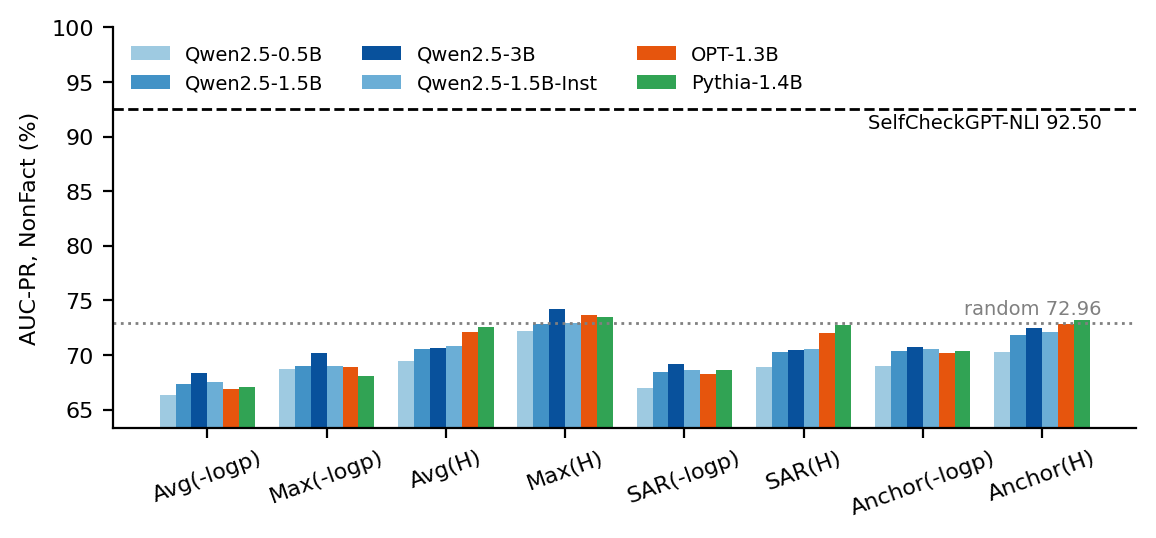

In [49]:
#@title Main results (paper Section 5.1, Table 2, Figure 1)
from IPython.display import Image
m = pd.read_csv('results/main_table.csv')
order = ['avg_nlp', 'max_nlp', 'avg_ent', 'max_ent', 'sar_nlp', 'sar_ent', 'anchor_nlp', 'anchor_ent']
t = m[m.model != 'selfcheck'].pivot(index='model', columns='score', values='NonFact')[order]
display(t.style.format('{:.2f}').map(lambda x: 'background-color:#c7e9c0;color:black' if x > 72.96 else ''))
print('AUROC of Avg(-log p) per proxy (50 = chance):', m[m.score == 'avg_nlp'].set_index('model').AUROC.round(1).to_dict())
display(Image('paper/figures/fig_main_aucpr.png', width=900))

**Reading.** All 48 proxy scores are at or below random (best: 74.19). For −log p the AUROC is 40–43, below 50: the ranking is *reversed*, meaning the proxies find hallucinated sentences **more** predictable than correct ones.

## 7. RQ2 — Does anchor weighting help?

,comparison,point,lo,hi,p_le_0,CI excludes 0
43,qwen0.5b::anchor_nlp - qwen0.5b::avg_nlp,2.61,1.28,4.22,0.00,True
45,qwen0.5b::sar_nlp - qwen0.5b::avg_nlp,0.60,-0.36,1.48,0.09,False
49,qwen1.5b::anchor_nlp - qwen1.5b::avg_nlp,3.03,1.51,4.67,0.00,True
51,qwen1.5b::sar_nlp - qwen1.5b::avg_nlp,1.17,0.22,2.03,0.00,True
55,qwen3b::anchor_nlp - qwen3b::avg_nlp,2.33,0.88,3.88,0.00,True
57,qwen3b::sar_nlp - qwen3b::avg_nlp,0.83,-0.05,1.70,0.04,False
61,opt1.3b::anchor_nlp - opt1.3b::avg_nlp,3.32,1.65,5.03,0.00,True
63,opt1.3b::sar_nlp - opt1.3b::avg_nlp,1.38,0.43,2.33,0.00,True
67,pythia1.4b::anchor_nlp - pythia1.4b::avg_nlp,3.33,1.68,4.99,0.00,True
69,pythia1.4b::sar_nlp - pythia1.4b::avg_nlp,1.57,0.64,2.44,0.00,True


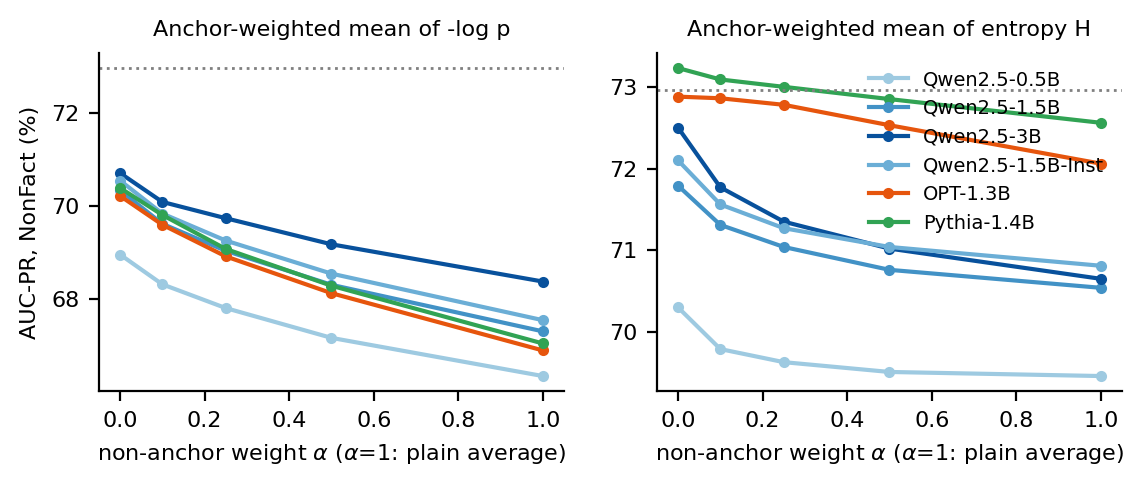

In [50]:
#@title Paired bootstrap differences (paper Section 5.2, Table 4) and alpha ablation (Figure 2)
b = pd.read_csv('results/bootstrap_ci.csv')
d = b[b.comparison.str.contains(' - ', regex=False)].copy()
d['CI excludes 0'] = (d.lo > 0) | (d.hi < 0)
display(d[d.comparison.str.contains('anchor_nlp - .*avg_nlp|sar_nlp - .*avg_nlp', regex=True)].round(2))
display(Image('paper/figures/fig_alpha_sensitivity.png', width=900))

**Reading.** Anchor weighting raises AUC-PR by +2.3 to +3.3 in all six proxies (every CI excludes 0) and beats SAR. But AUROC only moves from about 42 towards 50: it **cancels the reversed signal**; it does not detect hallucinations.

## 8. RQ3 — Two-stage screening

q,0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0
token-score selector,70.65,73.08,75.56,77.36,79.41,81.65,84.17,86.38,88.34,90.11,92.5
random selector (mean of 10 seeds),70.65,73.85,76.28,78.51,80.65,82.72,84.75,86.66,88.59,90.50,92.5


,N,NonFact,AUROC
0,1,88.03,76.15
1,2,89.97,79.65
2,3,90.98,81.41
3,5,91.70,82.53
4,10,92.20,83.42
5,20,92.50,83.69


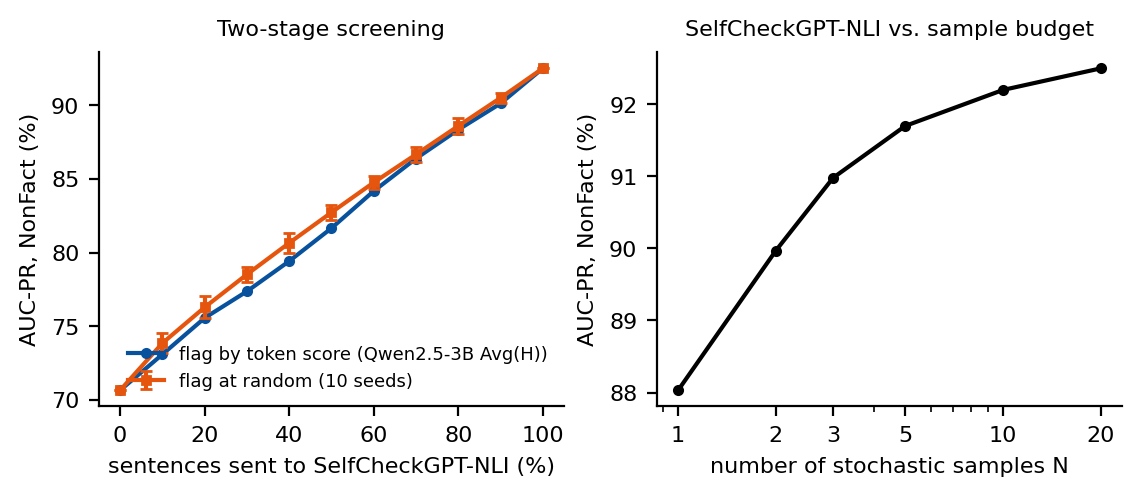

In [51]:
#@title Cascade vs. random routing (paper Section 5.3, Figure 3)
c = pd.read_csv('results/cascade.csv')
s1 = c[c.selector == 'stage1'].set_index('q').NonFact.rename('token-score selector')
r = c[c.selector == 'random'].groupby('q').NonFact.mean().rename('random selector (mean of 10 seeds)')
display(pd.concat([s1, r], axis=1).round(2).T)
display(pd.read_csv('results/nli_n_sensitivity.csv')[['N', 'NonFact', 'AUROC']])
display(Image('paper/figures/fig_cascade_nli.png', width=900))

**Reading.** The token-score selector is 0.25–1.24 points *worse* than random routing at every budget. A cheaper fix is fewer NLI samples: N = 5 keeps 91.70 of the 92.50 AUC-PR.

## 9. Error analysis (exploratory)

,model,score,AUROC_as_specified,AUROC_within_passage_centred,passage_mean_vs_halluc_rate_pearson
0,opt1.3b,avg_nlp,41.2,51.5,-44.9
2,opt1.3b,avg_ent,48.5,53.1,-11.3
6,pythia1.4b,avg_nlp,40.8,51.5,-49.0
8,pythia1.4b,avg_ent,49.0,53.1,-12.0
12,qwen0.5b,avg_nlp,40.0,49.9,-46.7
14,qwen0.5b,avg_ent,44.7,49.9,-20.5
18,qwen1.5b,avg_nlp,41.7,50.3,-43.2
20,qwen1.5b,avg_ent,46.8,50.9,-18.1
24,qwen1.5b-inst,avg_nlp,42.3,50.6,-42.4
26,qwen1.5b-inst,avg_ent,47.4,51.2,-16.2


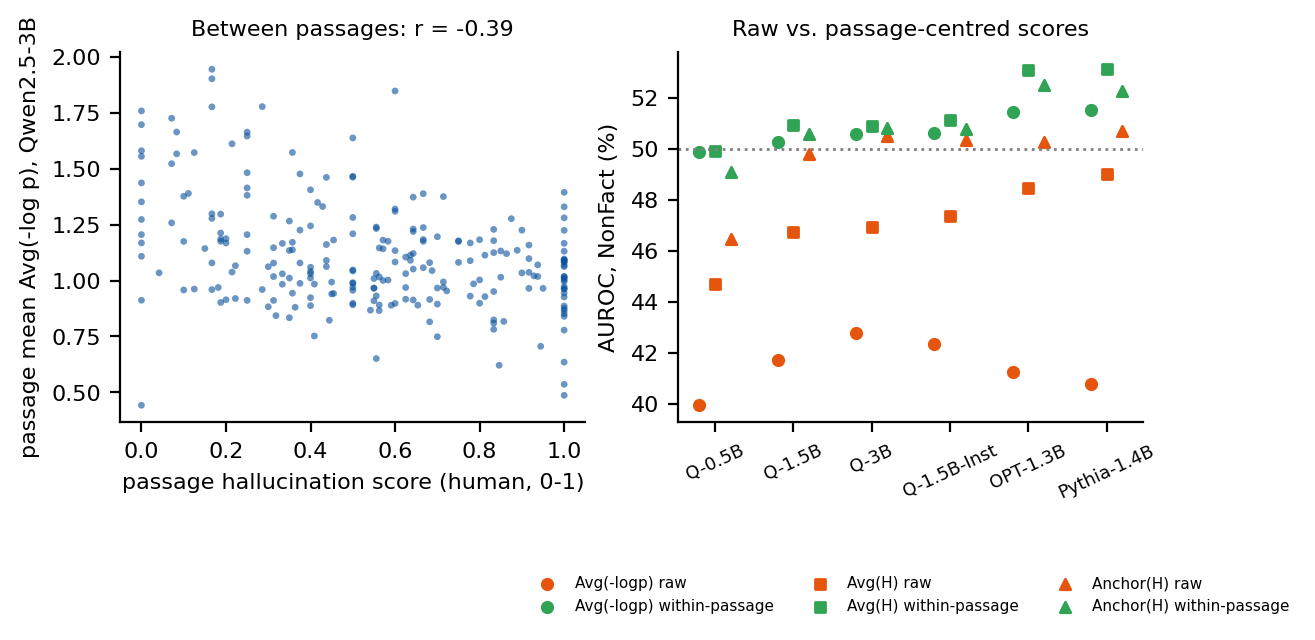

In [52]:
#@title Why the signal is reversed (paper Section 6, Figure 4)
dd = pd.read_csv('results/diagnostics_direction.csv')
cols = ['model', 'score', 'AUROC_as_specified', 'AUROC_within_passage_centred', 'passage_mean_vs_halluc_rate_pearson']
display(dd[dd.score.isin(['avg_nlp', 'avg_ent'])][cols].round(1))
display(Image('paper/figures/fig_passage_confound.png', width=900))

**Reading.** The effect lies *between* passages: fully fabricated biographies are generic and easy to predict (r ≈ −0.4). Within a passage, the scores are at chance (AUROC 48–53).

## 10. Conclusion
* Baselines reproduced exactly (random 72.96; SelfCheckGPT-NLI 92.50).
* Small proxy models (≤ 3B) **cannot** detect GPT-3 hallucinations; the log-probability signal is reversed.
* Anchor weighting is consistently *less wrong* than the plain average and SAR, but it is not a detector.
* A token-score cascade saves nothing. Use SelfCheckGPT-NLI with 3–5 samples, or the generator's own probabilities.
